# Predicting recorded OOB before a visit

Two eras are evaluated separately. Features use only earlier timestamps of the same business, plus calendar month and the explicitly declared prior chain threshold. Planned inspection type is a separate live variant that assumes the dispatch program is known in advance. The backtest uses inspection-event times; publication delays and later identity corrections are unobserved.

In [1]:
import os
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(root)
os.environ["OMP_NUM_THREADS"] = "4"
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from storefronts.gold import pipeline
from storefronts.notebook_tools import finish, style

style()

The target is whether a visit record ends in OOB, predicted from earlier business history, calendar information and the declared chain flag. Planned inspection type is a separate live variant. The systems are tested separately: the archive model fits 2015 to 2017, calibrates on 2018 and tests on 2019; the live model fits January to September 2024, calibrates on October to December 2024 and tests on 2025. Test base rates are 14.3% and 17.4%, respectively.

## Temporal protocol and baseline

No hyperparameter search. Archive: fit 2015–2017, calibrate on 2018, test 2019. Live: fit January–September 2024, calibrate October–December 2024, test 2025. Base models are not refit on calibration records. Platt calibration uses validation labels only. Default LightGBM parameters; logistic max_iter=1000 is convergence control. Ties at every budget use SHA-256 of inspection ID. Unknown prior-positive ages rank last in the rule.

In [2]:
import warnings
from pprint import pprint

warnings.filterwarnings("ignore", message="IProgress not found.*")

from storefronts.modeling import run

pprint(pipeline("model_rows", era="archive"), width=100)
pprint(pipeline("model_rows", era="live"), width=100)
results = run(resamples=500)
display(pd.DataFrame(results["splits"]))
baseline = pd.DataFrame(
    [
        {
            "era": m["era"],
            "visits": m["visits"],
            "oob": m["oob"],
            "roc_auc": m["roc_auc"],
            "selected_top10": m["topk"][1]["selected"],
            "oob_top10": m["topk"][1]["oob"],
            "precision_top10": m["topk"][1]["precision"],
        }
        for m in results["models"]
        if m["ranker"] == "staleness_rule"
    ]
)
display(baseline)

[{'$match': {'source': 'archive', 'year': {'$in': [2015, 2016, 2017, 2018, 2019]}}},
 {'$sort': {'_id': 1}}]
[{'$match': {'source': 'live', 'year': {'$in': [2024, 2025]}}}, {'$sort': {'_id': 1}}]


archive logistic_history fitted


archive lightgbm_history fitted


archive complete 7.72 seconds


live logistic_history fitted


live lightgbm_history fitted


live lightgbm_planned_type fitted


live complete 8.11 seconds


,era,split,visits,oob,oob_share,businesses,first,last
0,archive,train_total,295247,31201,0.105678,106031,2015-01-02 09:13:00,2018-12-31 16:33:00
1,archive,fit,227834,22251,0.097663,90994,2015-01-02 09:13:00,2017-12-29 18:12:00
2,archive,validation,67413,8950,0.132764,41193,2018-01-02 08:39:00,2018-12-31 16:33:00
3,archive,test,65916,9448,0.143334,40414,2019-01-02 00:00:00,2019-12-31 16:51:00
4,live,train_total,94896,14479,0.152578,33158,2024-01-02 00:00:00,2024-12-31 00:00:00
5,live,fit,68824,10488,0.152389,26911,2024-01-02 00:00:00,2024-09-30 00:00:00
6,live,validation,26072,3991,0.153076,11511,2024-10-01 00:00:00,2024-12-31 00:00:00
7,live,test,88745,15423,0.173790,38825,2025-01-02 00:00:00,2025-12-31 00:00:00


,era,visits,oob,roc_auc,selected_top10,oob_top10,precision_top10
0,archive,65916,9448,0.776066,6592,3596,0.545510
1,live,88745,15423,0.735506,8875,4855,0.547042


Ranking visits by months since the last positive observation is a strong baseline: ROC-AUC 0.776 and 54.6% precision in the top 10% of 2019 visits, and 0.736 and 54.7% in 2025, about three times the base rate. Every model here is judged against this one-line rule, not against random routing. The temporal fitting and calibration slices keep test-year outcomes out of model selection and probability calibration.

## Discrimination and budget curves

Intervals use 500 paired business-ID cluster bootstrap resamples of each test set, conditional on the fitted models. Model-minus-rule intervals use the same resamples. AP is average precision with score ties handled exactly. These intervals do not capture training uncertainty or changes in dispatch selection.

,era,ranker,visits,oob,base_rate,roc_auc,average_precision,average_precision_ci95,p10_ci95,delta_ap_rule,delta_ap_rule_ci95,delta_p10_rule,delta_p10_rule_ci95
0,archive,staleness_rule,65916,9448,0.143334,0.776066,0.436582,"[0.424286, 0.447332]","[0.532337, 0.558672]",0.000000,"[0.0, 0.0]",0.000000,"[0.0, 0.0]"
1,archive,logistic_history,65916,9448,0.143334,0.833885,0.558184,"[0.546032, 0.570108]","[0.620094, 0.647431]",0.121602,"[0.113293, 0.129785]",0.088744,"[0.07899, 0.097558]"
2,archive,lightgbm_history,65916,9448,0.143334,0.816400,0.489352,"[0.477697, 0.501316]","[0.523918, 0.553805]",0.052770,"[0.039909, 0.06665]",-0.007130,"[-0.021039, 0.00851]"
3,live,staleness_rule,88745,15423,0.173790,0.735506,0.429716,"[0.418096, 0.440737]","[0.534407, 0.559412]",0.000000,"[0.0, 0.0]",0.000000,"[0.0, 0.0]"
4,live,logistic_history,88745,15423,0.173790,0.782671,0.465645,"[0.45374, 0.475862]","[0.556277, 0.582404]",0.035929,"[0.030329, 0.041006]",0.023437,"[0.014718, 0.031008]"
5,live,lightgbm_history,88745,15423,0.173790,0.791255,0.472317,"[0.460176, 0.484128]","[0.562386, 0.587984]",0.042602,"[0.033505, 0.050933]",0.029296,"[0.020168, 0.036916]"
6,live,lightgbm_planned_type,88745,15423,0.173790,0.815276,0.502803,"[0.491029, 0.514566]","[0.578541, 0.603717]",0.073087,"[0.064821, 0.081437]",0.044732,"[0.035053, 0.051324]"


,era,ranker,budget,selected,oob,precision,recall,violations,rest_visits,rest_oob,rest_violations,violation_rate,rest_violation_rate,scenario_net_violations_per_1000
0,archive,staleness_rule,0.05,3296,2143,0.650182,0.226820,227,62620,7305,16113,0.068871,0.257314,188.442598
1,archive,staleness_rule,0.10,6592,3596,0.545510,0.380610,585,59324,5852,15755,0.088744,0.265575,176.831552
2,archive,staleness_rule,0.20,13184,5494,0.416717,0.581499,1947,52732,3954,14393,0.147679,0.272946,125.267214
3,archive,logistic_history,0.05,3296,2449,0.743022,0.259208,185,62620,6999,16155,0.056129,0.257985,201.856029
4,archive,logistic_history,0.10,6592,4181,0.634254,0.442528,496,59324,5267,15844,0.075243,0.267076,191.833001
5,archive,logistic_history,0.20,13184,6160,0.467233,0.651990,1735,52732,3288,14605,0.131599,0.276967,145.367640
6,archive,lightgbm_history,0.05,3296,2347,0.712075,0.248412,259,62620,7101,16081,0.078580,0.256803,178.222841
7,archive,lightgbm_history,0.10,6592,3549,0.538380,0.375635,732,59324,5899,15608,0.111044,0.263098,152.053877
8,archive,lightgbm_history,0.20,13184,5176,0.392597,0.547841,2162,52732,4272,14178,0.163987,0.268869,104.882347
9,live,staleness_rule,0.05,4438,2699,0.608157,0.174998,202,84307,12724,17518,0.045516,0.207788,162.272204


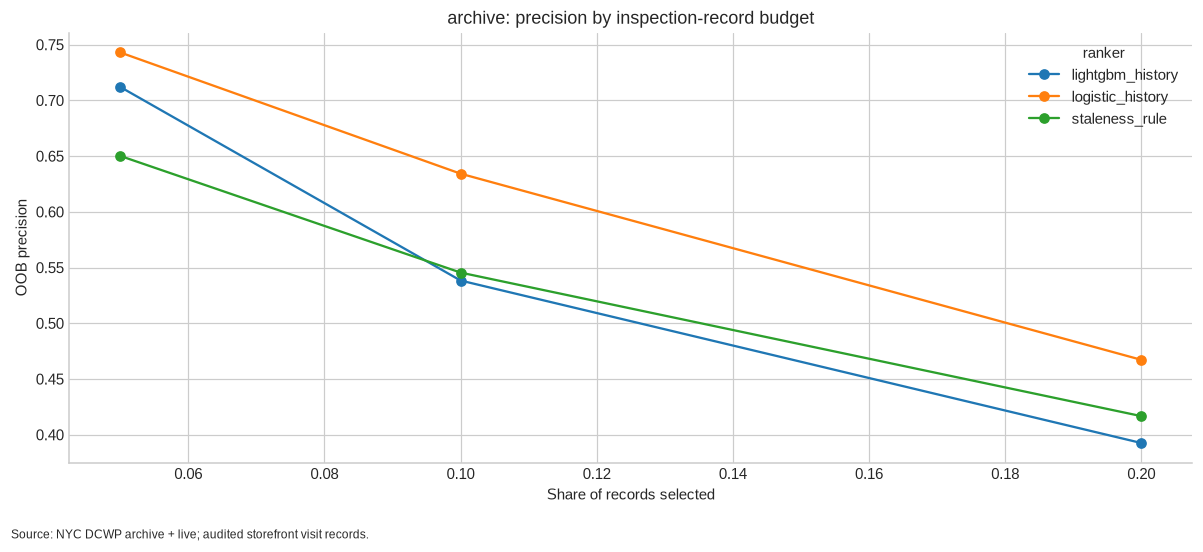

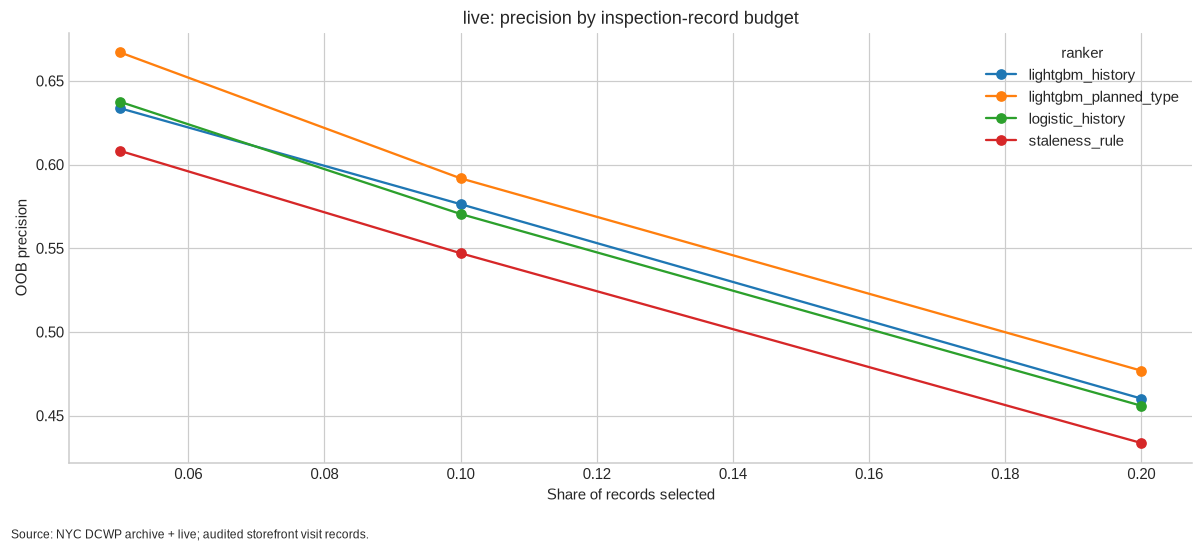

In [3]:
rows = []
curves = []
for m in results["models"]:
    rows.append(
        {
            k: m[k]
            for k in [
                "era",
                "ranker",
                "visits",
                "oob",
                "base_rate",
                "roc_auc",
                "average_precision",
                "average_precision_ci95",
                "p10_ci95",
                "delta_ap_rule",
                "delta_ap_rule_ci95",
                "delta_p10_rule",
                "delta_p10_rule_ci95",
            ]
        }
    )
    curves += [{"era": m["era"], "ranker": m["ranker"], **k} for k in m["topk"]]
display(pd.DataFrame(rows))
curves = pd.DataFrame(curves)
display(curves)
for era, f in curves.groupby("era"):
    ax = f.pivot(index="budget", columns="ranker", values="precision").plot(marker="o")
    finish(
        ax,
        era + ": precision by inspection-record budget",
        "Share of records selected",
        "OOB precision",
    )

In the archive, logistic regression adds 8.9 points of top-10% precision over the rule (63.4%; 95% interval for the gain 7.9 to 9.8) and 0.12 average precision. Default LightGBM does not beat the rule at the 10% budget (-0.7 points, interval -2.1 to +0.9) even though its average precision is higher, so summary and operating-budget metrics can disagree. In live data the gains are positive but small: logistic +2.3 points, history-only LightGBM +2.9 (57.6%), and LightGBM with planned type +4.5 (59.2%), all with intervals above zero. Most of the useful ranking is already achieved by one variable; the other features refine it rather than transform it.

## Calibration and confusion matrices

Calibration fits use validation data only; the plotted fractions are measured on held-out test data. The rule has no native probability; its probability is a validation-fitted logistic transformation of age, with unknown age -1. Platt calibration changes probabilities, not model ordering.

archive staleness_rule Brier raw: None calibrated: 0.09945873302960262 top-10% confusion: {'tp': 3596, 'fp': 2996, 'fn': 5852, 'tn': 53472}
archive logistic_history Brier raw: 0.08870398347682469 calibrated: 0.08846190931606439 top-10% confusion: {'tp': 4181, 'fp': 2411, 'fn': 5267, 'tn': 54057}
archive lightgbm_history Brier raw: 0.09670355612817054 calibrated: 0.09569119015556986 top-10% confusion: {'tp': 3549, 'fp': 3043, 'fn': 5899, 'tn': 53425}
live staleness_rule Brier raw: None calibrated: 0.12231951893492873 top-10% confusion: {'tp': 4855, 'fp': 4020, 'fn': 10568, 'tn': 69302}
live logistic_history Brier raw: 0.11878172803501232 calibrated: 0.1180588487651283 top-10% confusion: {'tp': 5063, 'fp': 3812, 'fn': 10360, 'tn': 69510}
live lightgbm_history Brier raw: 0.11690039123582945 calibrated: 0.11631036282039856 top-10% confusion: {'tp': 5115, 'fp': 3760, 'fn': 10308, 'tn': 69562}
live lightgbm_planned_type Brier raw: 0.11297300375010098 calibrated: 0.11259072429581696 top-10% c

,era,ranker,version,bin,visits,oob,mean_probability,observed_share
0,archive,staleness_rule,calibrated,"(0.0576, 0.0614]",15948,1074,0.059363,0.067344
1,archive,staleness_rule,calibrated,"(0.0614, 0.0651]",3858,69,0.062991,0.017885
2,archive,staleness_rule,calibrated,"(0.0651, 0.0741]",6578,177,0.069598,0.026908
3,archive,staleness_rule,calibrated,"(0.0741, 0.0851]",6580,334,0.079444,0.050760
4,archive,staleness_rule,calibrated,"(0.0851, 0.1]",6587,468,0.092512,0.071049
...,...,...,...,...,...,...,...,...
113,live,lightgbm_planned_type,raw,"(0.0976, 0.122]",8775,1074,0.112403,0.122393
114,live,lightgbm_planned_type,raw,"(0.122, 0.176]",8876,1446,0.147537,0.162911
115,live,lightgbm_planned_type,raw,"(0.176, 0.259]",8874,2135,0.212462,0.240590
116,live,lightgbm_planned_type,raw,"(0.259, 0.496]",8874,3212,0.378032,0.361956


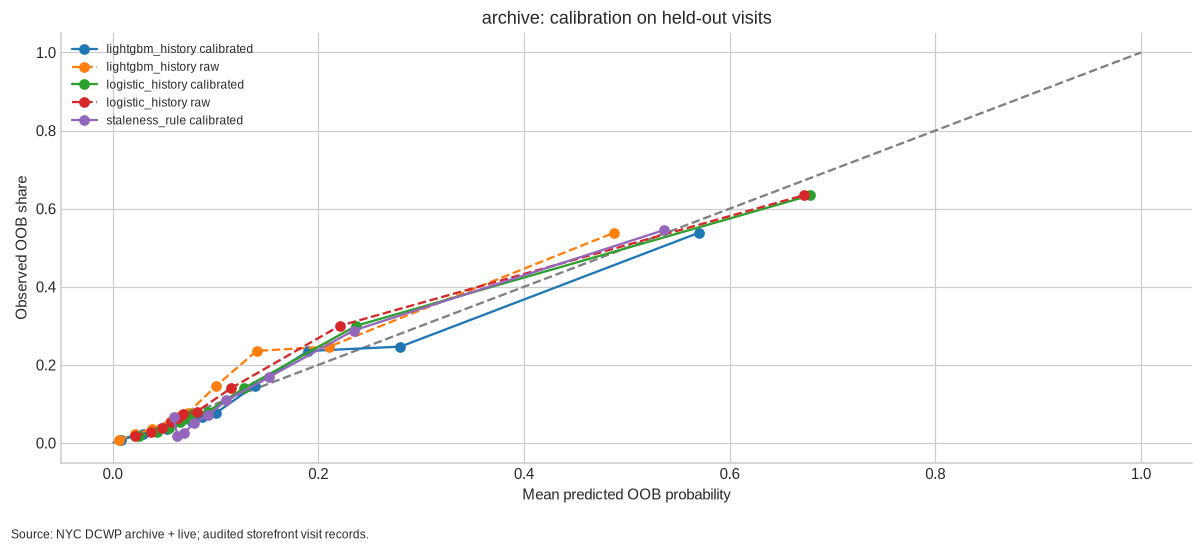

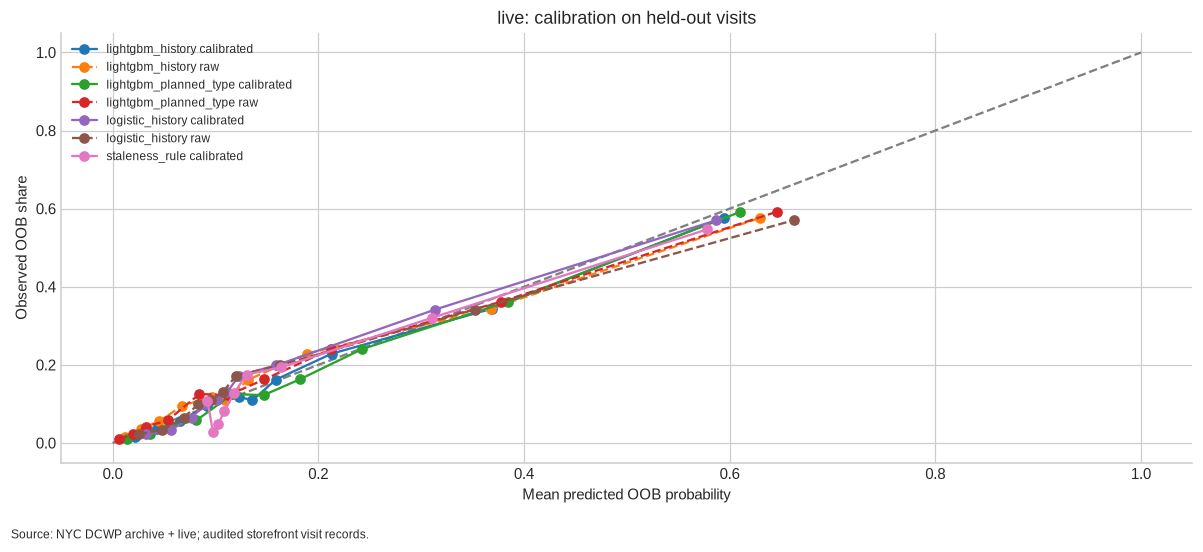

In [4]:
calibration_rows = []
for m in results["models"]:
    print(
        m["era"],
        m["ranker"],
        "Brier raw:",
        m["brier_uncalibrated"],
        "calibrated:",
        m["brier_calibrated"],
        "top-10% confusion:",
        m["confusion_top10"],
    )
    calibration_rows += [
        {"era": m["era"], "ranker": m["ranker"], "version": "calibrated", **x}
        for x in m["calibration"]
    ]
    calibration_rows += [
        {"era": m["era"], "ranker": m["ranker"], "version": "raw", **x}
        for x in m["calibration_uncalibrated"]
    ]
calibration = pd.DataFrame(calibration_rows)
display(calibration)
for era, f in calibration.groupby("era"):
    fig, ax = plt.subplots()
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--")
    for (ranker, version), g in f.groupby(["ranker", "version"]):
        ax.plot(
            g.mean_probability,
            g.observed_share,
            marker="o",
            label=ranker + " " + version,
            linestyle="--" if version == "raw" else "-",
        )
    ax.legend(fontsize=8)
    finish(
        ax,
        era + ": calibration on held-out visits",
        "Mean predicted OOB probability",
        "Observed OOB share",
    )

After validation-only Platt calibration, live history-only LightGBM is close in its highest probability bin: 59.4% predicted and 57.6% observed, with a Brier score of 0.116. Archive logistic under-predicts in its ninth bin, at 23.7% predicted and 30.0% observed, so its probabilities should not be treated as exact rates. At the top-10% budget, the live history model flags 8,875 visits: 5,115 OOB and 3,760 not OOB. It misses 10,308 OOB records, recalling about 33% at this budget. Most OOB records are not concentrated enough to be caught by reviewing one tenth of visits, limiting what a pre-dispatch screen can cover.

## Feature importance

Gain importance is from the fitted live history model. SHAP values describe 500 seeded held-out records; a permutation fallback is used if SHAP fails. Neither importance method identifies causal effects.

,feature,gain
0,numeric__months_since_last_positive,62314.899581
1,numeric__prior_visits,8683.034761
2,numeric__prior_oob_unresolved,8192.900191
3,numeric__prior_violations,5883.339716
4,numeric__prior_oob,1627.547777
5,categorical__month_8,856.787268
6,categorical__month_9,744.219386
7,categorical__industry_group_tobacco_vape_cannabis,698.650653
8,categorical__borough_Brooklyn,614.814074
9,categorical__borough_Manhattan,602.979288


SHAP TreeExplainer; 500 seeded held-out records; descriptive only


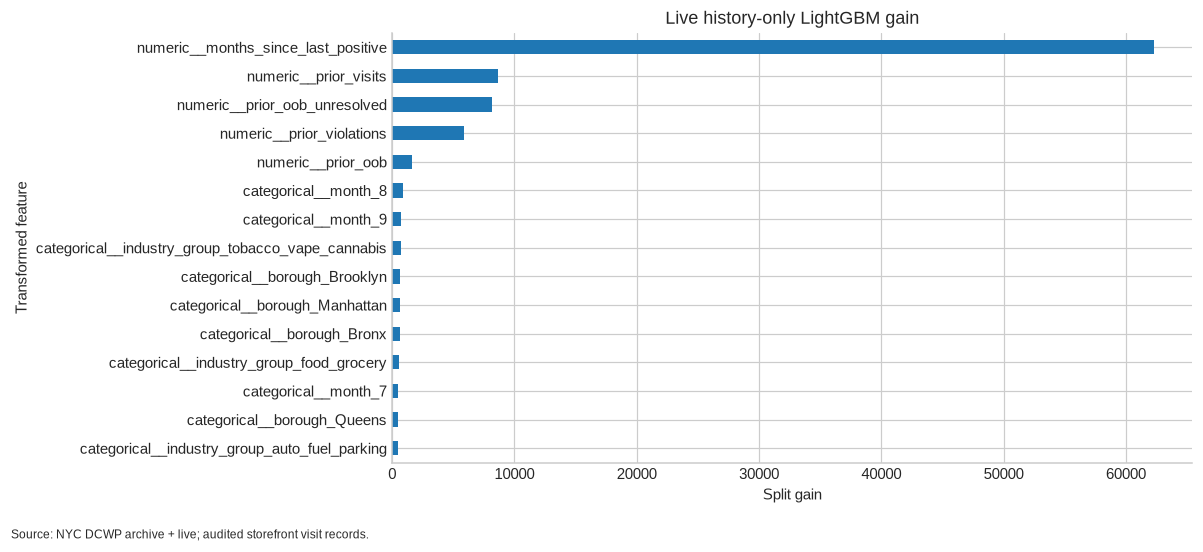

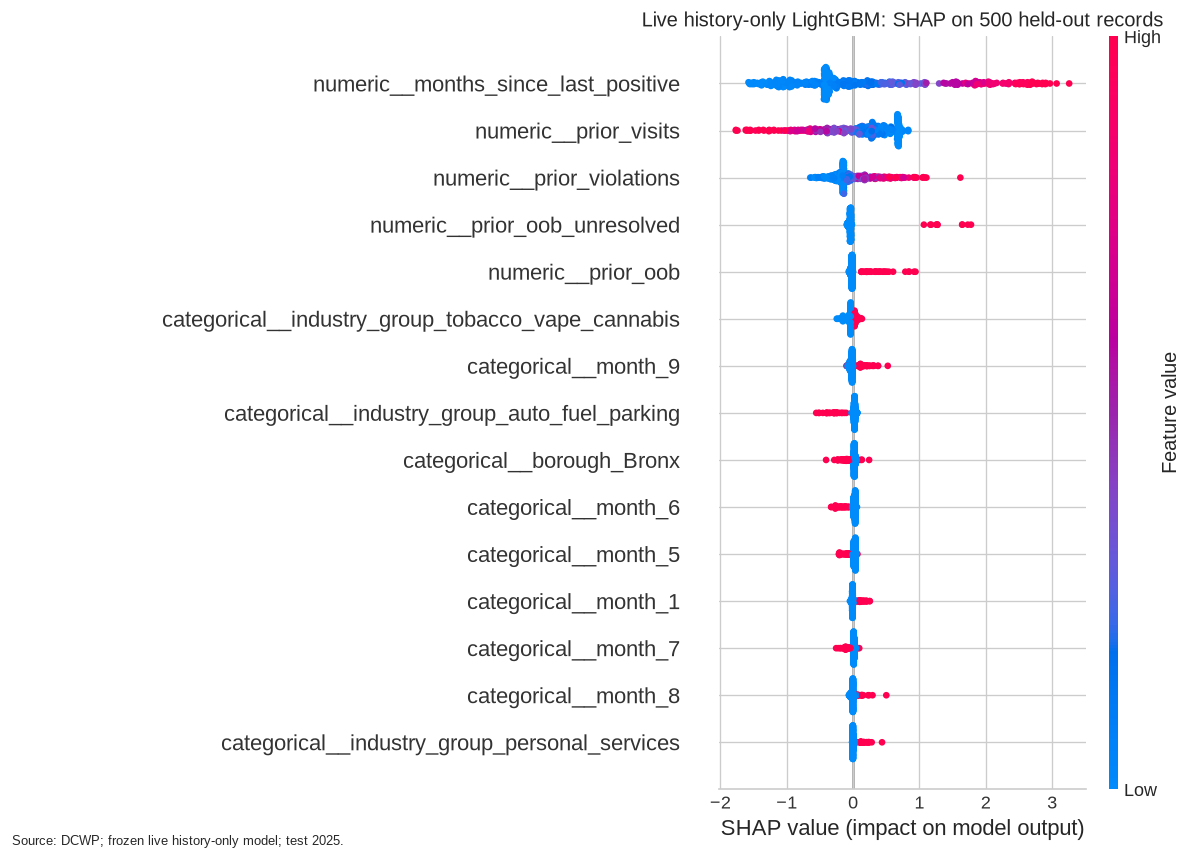

,feature,mean_absolute_shap
0,numeric__months_since_last_positive,0.912558
1,numeric__prior_visits,0.455506
2,numeric__prior_violations,0.239341
3,numeric__prior_oob_unresolved,0.074680
4,numeric__prior_oob,0.050078
5,categorical__industry_group_tobacco_vape_cannabis,0.047208
6,categorical__month_9,0.039983
7,categorical__industry_group_auto_fuel_parking,0.038986
8,categorical__borough_Bronx,0.034876
9,categorical__month_6,0.034356


In [5]:
from IPython.display import Image

importance = pd.DataFrame(results["importance"]["gain"])
display(importance)
print(results["importance"]["explanation_method"])
ax = importance.head(15).sort_values("gain").plot.barh(x="feature", y="gain", legend=False)
finish(ax, "Live history-only LightGBM gain", "Split gain", "Transformed feature")
display(Image(filename="reports/model_shap.png"))
display(pd.DataFrame(results["importance"]["shap_mean_absolute"]).head(10))

By LightGBM gain, the top three features are months since the last positive, prior visit count and unresolved prior OOB. By mean absolute SHAP value, they are months since the last positive, prior visit count and prior violation count. Positive-observation age ranks first in both. The SHAP summary associates older positives, unresolved OOB and higher prior violation counts with higher predicted risk; more prior visits generally lower it. Recency carries most of the signal, while history counts adjust the ranking. These are predictive associations, not causal effects of inspection or enforcement.

## Sensitivity checks

Models and predictions are frozen; each subset is reranked at its own budget. One record per business/timestamp keeps the lexicographically first inspection ID. Mixed-outcome blocks prevent reconstructing a physical trip from this choice. Cold starts have no prior industry or borough. Cross-switch exclusions remove all linked archive IDs, including retrospective looser links.

,era,ranker,subset,visits,oob,roc_auc,average_precision,p10
0,archive,staleness_rule,one_per_business_timestamp,58145,9162,0.778665,0.455560,0.568186
1,archive,staleness_rule,has_prior_history,55369,8705,0.803005,0.462073,0.567636
2,archive,staleness_rule,cold_start,10547,743,0.500000,0.070447,0.071090
3,archive,staleness_rule,exclude_cross_switch_links,65697,9448,0.776011,0.436975,0.545967
4,archive,logistic_history,one_per_business_timestamp,58145,9162,0.835627,0.576224,0.667068
5,archive,logistic_history,has_prior_history,55369,8705,0.850590,0.588602,0.675817
6,archive,logistic_history,cold_start,10547,743,0.551262,0.080761,0.088152
7,archive,logistic_history,exclude_cross_switch_links,65697,9448,0.833781,0.558463,0.634703
8,archive,lightgbm_history,one_per_business_timestamp,58145,9162,0.817968,0.511720,0.572141
9,archive,lightgbm_history,has_prior_history,55369,8705,0.825600,0.514088,0.579195


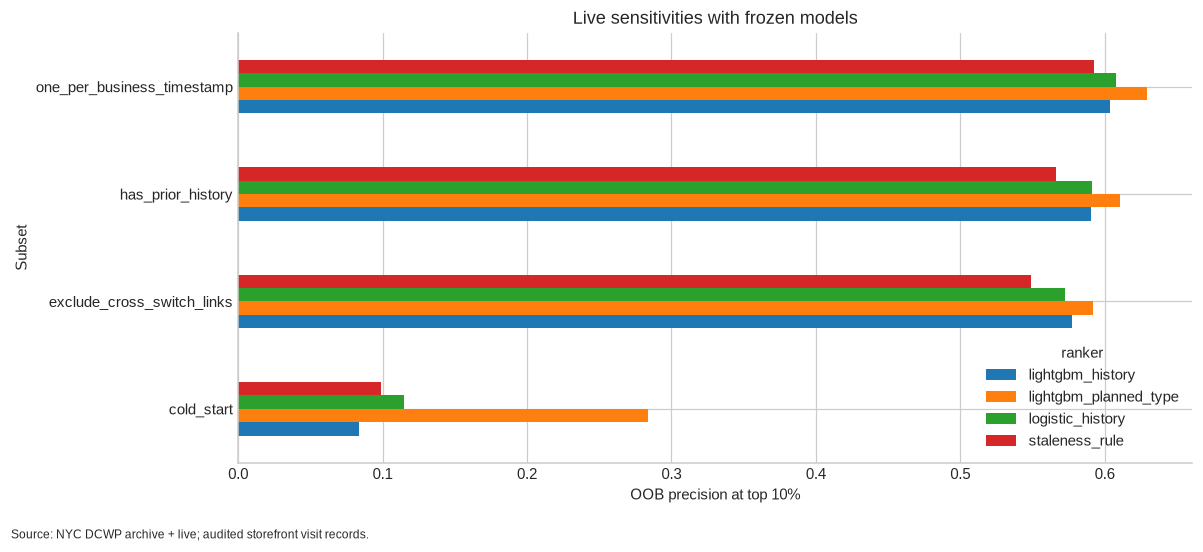

In [6]:
sensitivity = pd.json_normalize(results["sensitivities"])
sensitivity["p10"] = sensitivity.topk.map(lambda k: k[1]["precision"])
display(
    sensitivity[["era", "ranker", "subset", "visits", "oob", "roc_auc", "average_precision", "p10"]]
)
ax = (
    sensitivity.loc[sensitivity.era == "live"]
    .pivot(index="subset", columns="ranker", values="p10")
    .plot.barh()
)
finish(ax, "Live sensitivities with frozen models", "OOB precision at top 10%", "Subset")

The ranking advantage generally persists when keeping one record per business/timestamp, excluding cross-switch links or restricting to prior-history visits. Precision levels can move several points as those subsets change the base rate. Cold starts are the exception: history-model ROC-AUC ranges from 0.489 to 0.551, near chance, while planned-type LightGBM reaches 0.650. First observations account for 13,231/88,745 visits in 2025, about 15%, so a history-based screen has little information for that group. These checks retain frozen predictions rather than refitting models.

## Observed OOB–violation trade-off

Top 20% and the remainder were both inspected. Scenario = 1,000 × (remaining-set violation rate − selected-set violation rate), assuming equal visit costs and exchangeable feasible replacement records. Program-held-fixed scenarios weight remaining-set yields by selected program counts, excluding programs without comparisons. These are associations, not measured intervention gains. They do not support automatic cancellation.

,era,ranker,budget,selected,oob,precision,recall,violations,rest_visits,rest_oob,rest_violations,violation_rate,rest_violation_rate,scenario_net_violations_per_1000
2,archive,staleness_rule,0.2,13184,5494,0.416717,0.581499,1947,52732,3954,14393,0.147679,0.272946,125.267214
5,archive,logistic_history,0.2,13184,6160,0.467233,0.651990,1735,52732,3288,14605,0.131599,0.276967,145.367640
8,archive,lightgbm_history,0.2,13184,5176,0.392597,0.547841,2162,52732,4272,14178,0.163987,0.268869,104.882347
11,live,staleness_rule,0.2,17749,7697,0.433658,0.499060,1734,70996,7726,15986,0.097696,0.225168,127.471970
14,live,logistic_history,0.2,17749,8092,0.455913,0.524671,1711,70996,7331,16009,0.096400,0.225492,129.091780
17,live,lightgbm_history,0.2,17749,8168,0.460195,0.529599,1774,70996,7255,15946,0.099949,0.224604,124.654910
20,live,lightgbm_planned_type,0.2,17749,8464,0.476872,0.548791,1930,70996,6959,15790,0.108739,0.222407,113.668376


staleness_rule program-held-fixed scenario 212.9482038064865
logistic_history program-held-fixed scenario 204.14672678422735
lightgbm_history program-held-fixed scenario 192.40953254856692
lightgbm_planned_type program-held-fixed scenario 200.40597985094882


,ranker,program,top_visits,top_oob,top_violations,rest_visits,rest_oob,rest_violations
0,staleness_rule,Business Education,129,0,0,4396,40,0
1,staleness_rule,Business Info Check,1,0,0,7,0,0
2,staleness_rule,Check UNL - FTR,220,150,13,900,405,182
3,staleness_rule,Consumer Request to Inspect,191,43,70,1990,330,920
4,staleness_rule,External to DCA - Community Board,4,0,3,11,5,4
...,...,...,...,...,...,...,...,...
99,lightgbm_planned_type,Tobacco - State Suspension,0,0,0,32,1,6
100,lightgbm_planned_type,Tobacco - T21,851,447,131,13126,1106,3789
101,lightgbm_planned_type,WAM - Condemned Follow-up,0,0,0,3,0,0
102,lightgbm_planned_type,WAM - Other,0,0,0,108,3,2


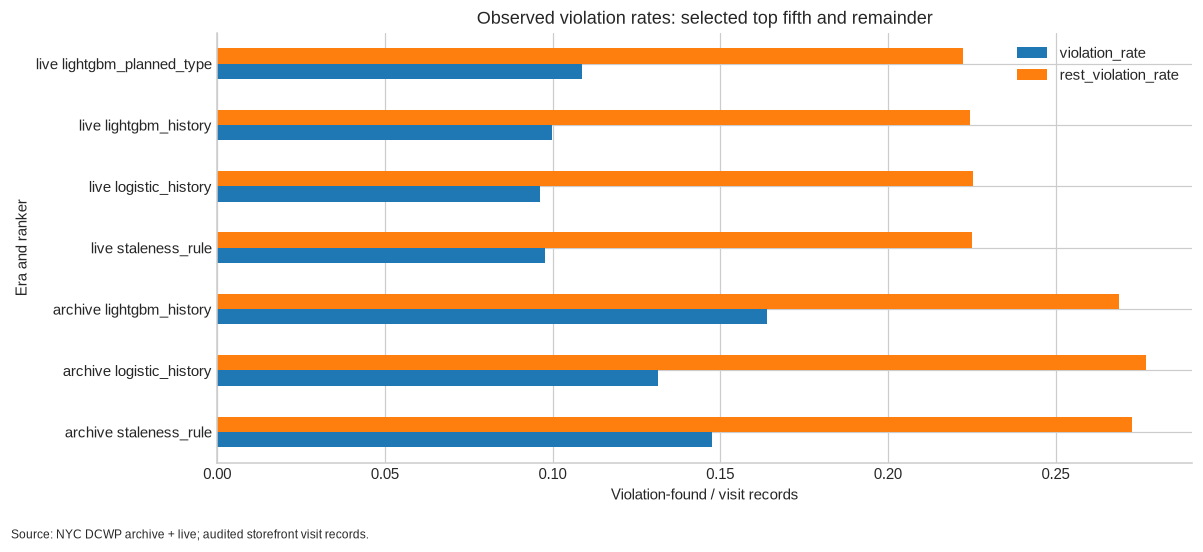

In [7]:
trade = curves.loc[curves.budget == 0.2]
display(trade)
program_rows = []
for m in results["models"]:
    if m["era"] == "live":
        print(
            m["ranker"],
            "program-held-fixed scenario",
            m["program_tradeoff"]["scenario_same_program_net_per_1000"],
        )
        program_rows += [{"ranker": m["ranker"], **r} for r in m["program_tradeoff"]["programs"]]
display(pd.DataFrame(program_rows))
ax = trade.assign(label=trade.era + " " + trade.ranker).plot.barh(
    x="label", y=["violation_rate", "rest_violation_rate"]
)
finish(
    ax,
    "Observed violation rates: selected top fifth and remainder",
    "Violation-found / visit records",
    "Era and ranker",
)

The highest-scored visits still carry enforcement value. The 2025 history-only model's top 20% contains 8,168 OOB records but also 1,774 visits that found a violation. Holding the selected program mix fixed, remaining-set violation rates imply about 192 additional findings per 1,000 records moved, under an exchangeability and feasible-replacement assumption. This is an association, not a measured routing gain. It supports testing verification before dispatch, such as a license, phone or web check, rather than cancelling flagged visits outright.

## Proposed randomized pre-dispatch verification design

**Proposed design only; no deployment or cancellations.** Randomize scheduled business/day blocks among the top-scored tenth within program, borough and week, to usual dispatch or a documented pre-dispatch verification workflow with human review. Keep enforcement-required cases in both arms. Record verification success, all dispatches, outcomes, staff time, closure-confirmation value and violation counts; audit a random sample of deferred cases with a visit. Primary outcome: OOB-record share per completed visit, with violation findings per inspector-day as a guardrail. Completion can change with treatment, so this rate describes the completed-work mix. Secondary outcomes: intention-to-treat OOB and violations per randomized scheduled block, dispatch completion, cost, coverage and delays. Pilot operational intent and within-business clustering first; no causal gain is estimated here.

The sample-size sketch below assumes independent binary records, two-sided 5% alpha, 80% power and a 10 percentage-point reduction from the observed 2025 history-model top-10% OOB share. Inflate for business/day clustering and noncompliance after a pilot; a record-based sketch is not the final randomization-unit sample size.

In [8]:
from scipy.stats import norm

m = next(m for m in results["models"] if m["era"] == "live" and m["ranker"] == "lightgbm_history")
p0 = m["topk"][1]["precision"]
p1 = max(0, p0 - 0.10)
pbar = (p0 + p1) / 2
n = int(
    __import__("math").ceil(
        (
            norm.ppf(0.975) * (2 * pbar * (1 - pbar)) ** 0.5
            + norm.ppf(0.8) * (p0 * (1 - p0) + p1 * (1 - p1)) ** 0.5
        )
        ** 2
        / (p0 - p1) ** 2
    )
)
display(
    pd.DataFrame(
        [
            {
                "observed_top10_records": m["topk"][1]["selected"],
                "observed_oob": m["topk"][1]["oob"],
                "p0": p0,
                "assumed_p1": p1,
                "independent_records_per_arm": n,
            }
        ]
    )
)

,observed_top10_records,observed_oob,p0,assumed_p1,independent_records_per_arm
0,8875,5115,0.576338,0.476338,391


The proposed test randomizes scheduled business/day blocks in the top-scored band between usual dispatch and documented pre-dispatch verification. The primary outcome is the OOB-record rate per completed visit, with violation findings per inspector-day as a guardrail. Completion can change with treatment, so this rate describes the completed-work mix; OOB and violations per randomized scheduled block are secondary intention-to-treat outcomes. Visits cluster within businesses, inspectors and programs, so a pilot is needed before fixing the sample size. The design would test what this observational analysis cannot establish: whether verification reduces visits without missing violations.